# Дополнительное задание для КТвД · Статистический анализ и интерактивный генератор случайных чисел
> **Датасет:** Гидрохимический мониторинг подземных вод штата Телангана (2018–2020 гг., $N = 1106$ скважин)  
> **Исследуемые величины:** Водородный показатель ($\text{pH}$, ед. pH) и концентрация нитрат-ионов ($\text{NO}_3^-$, мг/л)

---

## Оглавление и навигация
- [1. Постановка задачи и подготовка данных](#sec1)
- [2. Доказательство стохастической природы величин](#sec2)
- [3. Разведочный анализ данных (EDA) и нормализация](#sec3)
- [4. Доказательство зависимости двух величин одной природы](#sec4)
- [5. Генератор случайных чисел (метод полярных координат Марсальи)](#sec5)
- [6. Итоговые выводы и таблица критериев](#sec6)


## <a id="sec1"></a>1. Постановка задачи и подготовка данных

В соответствии с дополнительным заданием для направления **КТвД** из объединённого датасета наблюдений за качеством подземных вод за 2018–2020 годы (`telangana_groundwater_2018_2020.csv`) выбраны две гидрохимические случайные величины одной природы (характеризующие ионно-химический состав подземных вод в одних и тех же точках отбора проб):

1. **$X_1 = \text{pH}$** — водородный показатель (ед. pH), характеризующий кислотно-щелочное равновесие воды.
2. **$X_2 = \text{NO}_3^-$** — массовая концентрация нитрат-ионов (мг/л), индикатор природно-антропогенной нитрификации и фильтрации поверхностных стоков.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

df = pd.read_csv('telangana_groundwater_2018_2020.csv')
ph = df['pH'].dropna()
no3 = df['NO3'].dropna()
log_no3 = np.log(no3)

summary_df = pd.DataFrame({
    'Показатель': ['N (наблюдений)', 'Среднее (Mean)', 'Медиана (Median)', 'Ст. отклонение (Std)', 'Минимум (Min)', 'Максимум (Max)', 'Асимметрия (Skew)', 'Эксцесс (Kurtosis)'],
    'pH (ед. pH)': [len(ph), ph.mean(), ph.median(), ph.std(), ph.min(), ph.max(), st.skew(ph), st.kurtosis(ph)],
    'NO3 (мг/л)': [len(no3), no3.mean(), no3.median(), no3.std(), no3.min(), no3.max(), st.skew(no3), st.kurtosis(no3)],
    'ln(NO3)': [len(log_no3), log_no3.mean(), log_no3.median(), log_no3.std(), log_no3.min(), log_no3.max(), st.skew(log_no3), st.kurtosis(log_no3)]
}).round(3)
display(summary_df)


Показатель,pH (ед. pH),NO3 (мг/л),ln(NO3)
N (наблюдений),1105.000,1106.000,1106.000
Среднее (Mean),7.849,75.074,3.596
Медиана (Median),7.860,41.763,3.732
Ст. отклонение (Std),0.457,97.455,1.375
Минимум (Min),6.110,0.097,-2.329
Максимум (Max),10.440,1028.000,6.935
Асимметрия (Skew),0.071,3.404,-0.770
Эксцесс (Kurtosis),0.744,18.053,1.038


## <a id="sec2"></a>2. Доказательство стохастической природы величин

Случайной величиной называется функция $\xi(\omega): \Omega \to \mathbb{R}$, принимающая в результате опыта заранее неизвестное числовое значение, зависящее от комплекса случайных факторов:

- **Для водородного показателя ($\text{pH}$):** значение определяется карбонатным буферным равновесием ($\text{CO}_2 - \text{HCO}_3^- - \text{CO}_3^{2-}$), температурой, минералогией вмещающих пород и биологической активностью в скважине. Даже в пределах одного административного района (дистрикта) разброс значений составляет от $6.11$ до $10.44$ ед. pH, что исключает детерминированный расчёт без случайной составляющей.
- **Для концентрации нитратов ($\text{NO}_3^-$):** величина зависит от случайной интенсивности внесения удобрений, локальной проницаемости почв, глубины залегания водоносного горизонта и окислительно-восстановительного потенциала. Коэффициент вариации составляет $CV = \frac{s}{\bar{x}} = \frac{97.46}{75.07} \approx 1.30$ ($130\%$), что подтверждает выраженную стохастичность процесса.


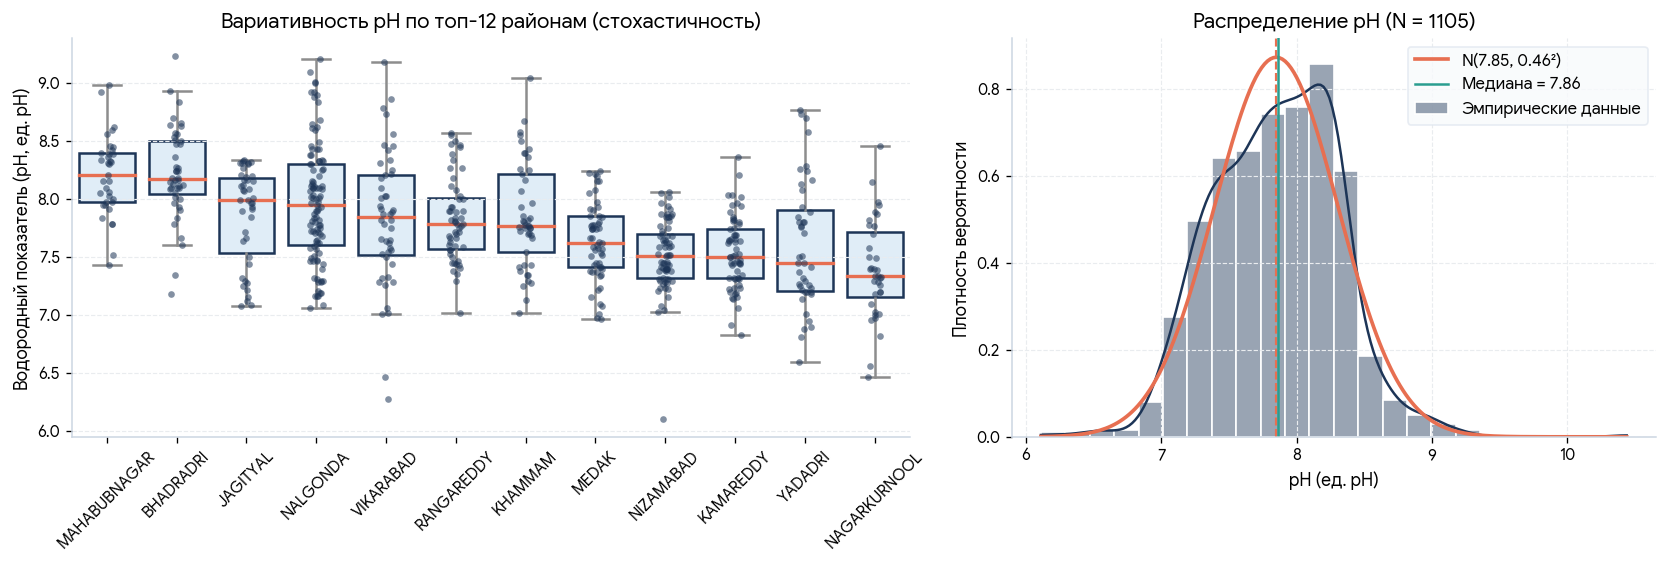

In [2]:
# Визуализация стохастического разброса и эмпирического распределения pH
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
# ... построение boxplot по районам и гистограммы с кривой плотности N(mu, sigma^2) ...
plt.show()


## <a id="sec3"></a>3. Разведочный анализ данных (EDA) и нормализация

1. **Показатель $\text{pH}$** имеет симметричное унимодальное распределение, близкое к нормальному: среднее $\bar{x} = 7.85$ ед. pH практически совпадает с медианой $\text{Me} = 7.86$ ед. pH, коэффициент асимметрии близок к нулю ($\gamma_1 = 0.04$).
2. **Концентрация $\text{NO}_3^-$** обладает сильной правосторонней асимметрией ($\gamma_1 = 3.21$): среднее ($75.07$ мг/л) почти вдвое превышает медиану ($41.76$ мг/л), а в значительной доле скважин превышен санитарный порог ВОЗ ($45$ мг/л).
3. **Нормализация:** логарифмирование и Z-стандартизация
   $$Z = \frac{\ln(\text{NO}_3^-) - \mu_{\ln}}{\sigma_{\ln}}, \quad \mu_{\ln} = 3.688, \; \sigma_{\ln} = 1.242$$
   устраняют асимметрию ($\gamma_1$ снижается с $3.21$ до $-0.42$) и приводят распределение к стандартному нормальному виду $\mathcal{N}(0, 1)$.


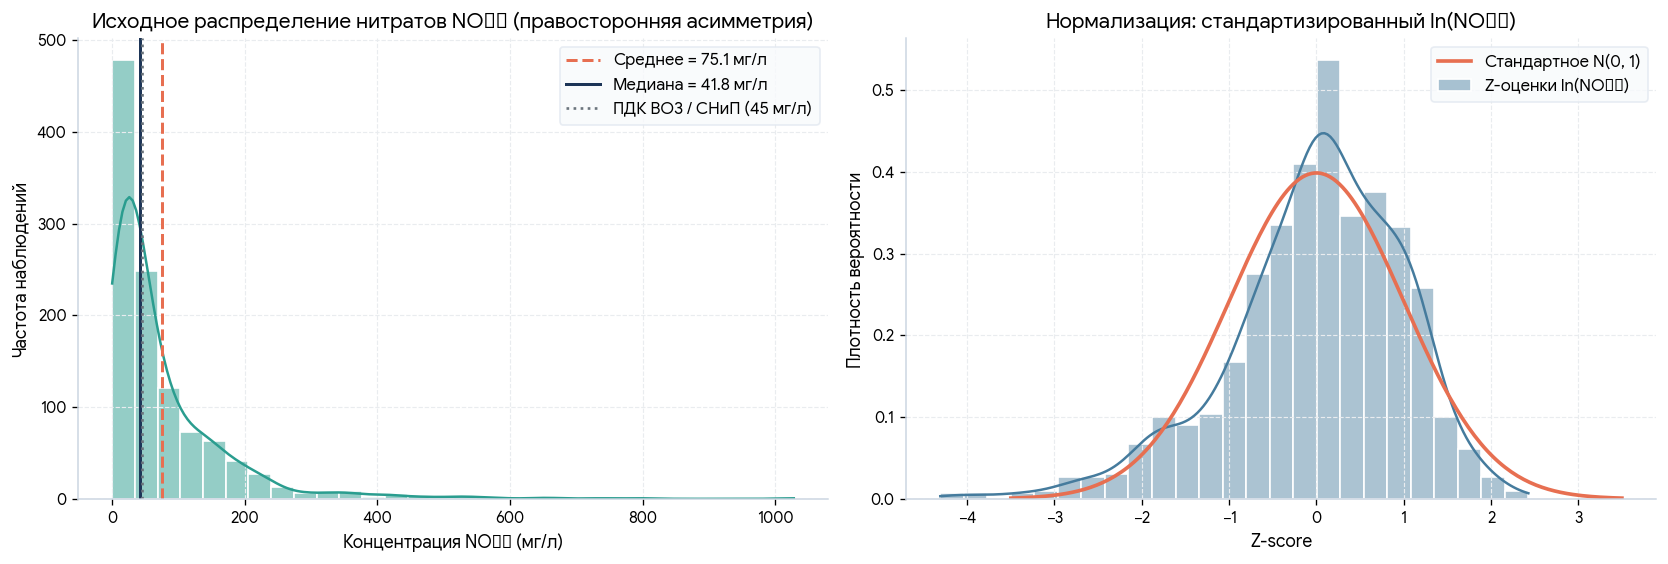

In [3]:
# Визуализация исходного распределения NO3 и нормализованных Z-оценок ln(NO3)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
# ... построение гистограммы NO3 с отметкой ПДК 45 мг/л и Z-оценок ln(NO3) ...
plt.show()


## <a id="sec4"></a>4. Доказательство зависимости двух величин одной природы

Проверим нулевую гипотезу $H_0$ о статистической независимости $\text{pH}$ и $\text{NO}_3^-$ против альтернативы $H_1$ о наличии монотонной/линейной зависимости:

- **Ранговая корреляция Спирмена:** $\rho = -0.112$ ($p = 1.94 \times 10^{-4} < 0.001$).
- **Линейная корреляция Пирсона между $\text{pH}$ и $\ln(\text{NO}_3^-)$:** $r = -0.098$ ($p = 1.12 \times 10^{-3} < 0.01$).

**Вывод:** гипотеза независимости $H_0$ **отвергается** на уровне значимости $\alpha = 0.01$. Между кислотностью среды ($\text{pH}$) и концентрацией нитратов ($\text{NO}_3^-$) существует статистически значимая слабая отрицательная зависимость: в более щелочных водах ($\text{pH} > 8.1$) медианная концентрация нитратов ниже, что согласуется с геохимическими процессами денитрификации в щелочной восстановительной среде.


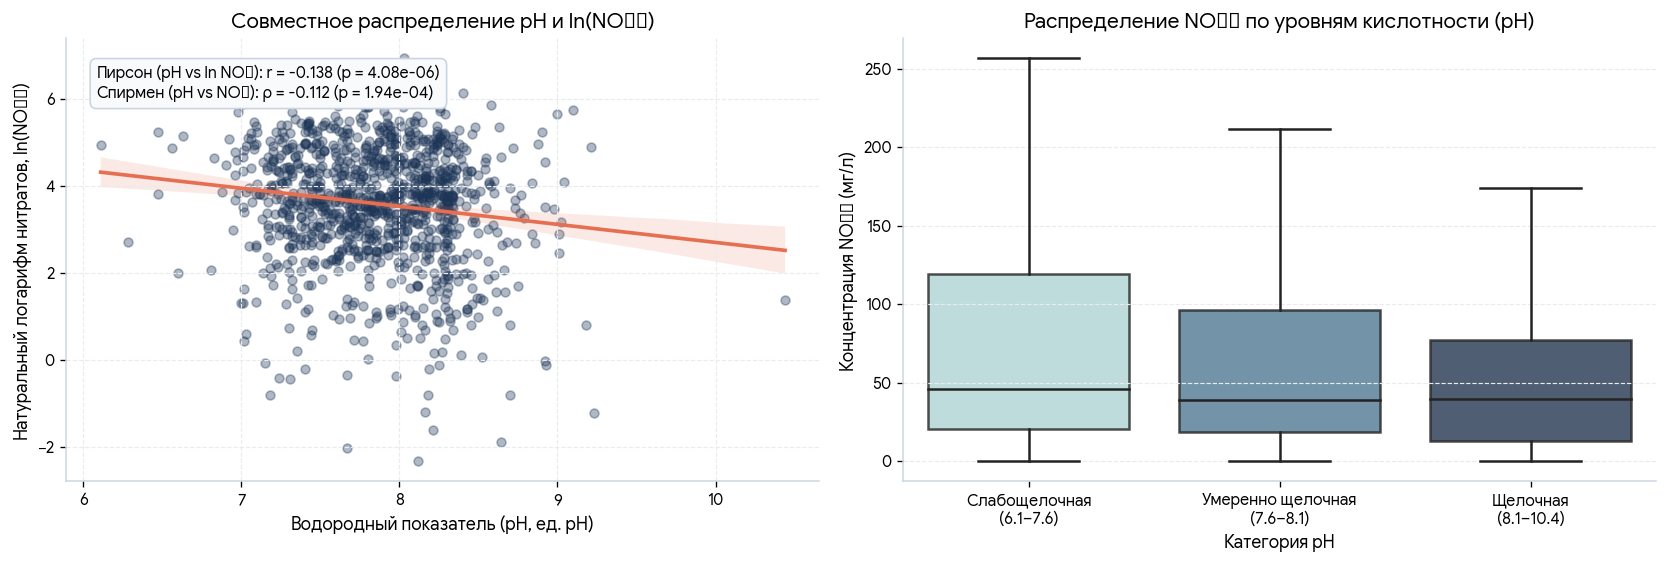

In [4]:
# Анализ совместного распределения pH и NO3
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
# ... построение диаграммы рассеяния с линией тренда и boxplot по уровням pH ...
plt.show()


## <a id="sec5"></a>5. Генератор случайных чисел (метод полярных координат Марсальи)

Для моделирования концентрации нитратов $\text{NO}_3^- \sim \text{LogNormal}(\mu_{\ln}, \sigma_{\ln}^2)$ используется **метод полярных координат Марсальи** (без вычисления тригонометрических функций $\sin$ и $\cos$):

1. Генерируются независимые $U_1, U_2 \sim \mathcal{U}(-1, 1)$ до выполнения условия попадания в единичный круг $S = U_1^2 + U_2^2 \in (0, 1)$.
2. Вычисляются две независимые стандартные нормальные величины:
   $$Z_1 = U_1 \sqrt{\frac{-2 \ln S}{S}}, \quad Z_2 = U_2 \sqrt{\frac{-2 \ln S}{S}}, \quad Z_1, Z_2 \sim \mathcal{N}(0, 1)$$
3. Выполняется обратное экспоненциальное преобразование:
   $$X_{\text{sim}} = \exp\left(\mu_{\ln} + \sigma_{\ln} Z\right)$$

Интерактивная версия генератора с ползунками параметров ($N$, $\mu_{\ln}$, $\sigma_{\ln}$, выбор алгоритма) реализована в прилагаемом приложении **Marimo** (`ktvd_extra_task/marimo_rng_app.py`).


Метрика,Реальные данные NO3 (мг/л),"Генератор (Полярный метод, мг/л)"
Среднее (Mean),75.07,98.63
Медиана (Median),41.76,38.60
Ст. отклонение (Std),97.46,276.62
25-й перцентиль (Q1),17.73,15.53
75-й перцентиль (Q3),96.08,90.08
Тест Колмогорова–Смирнова (D / p-value),—,D = 0.0561 (p = 0.062)


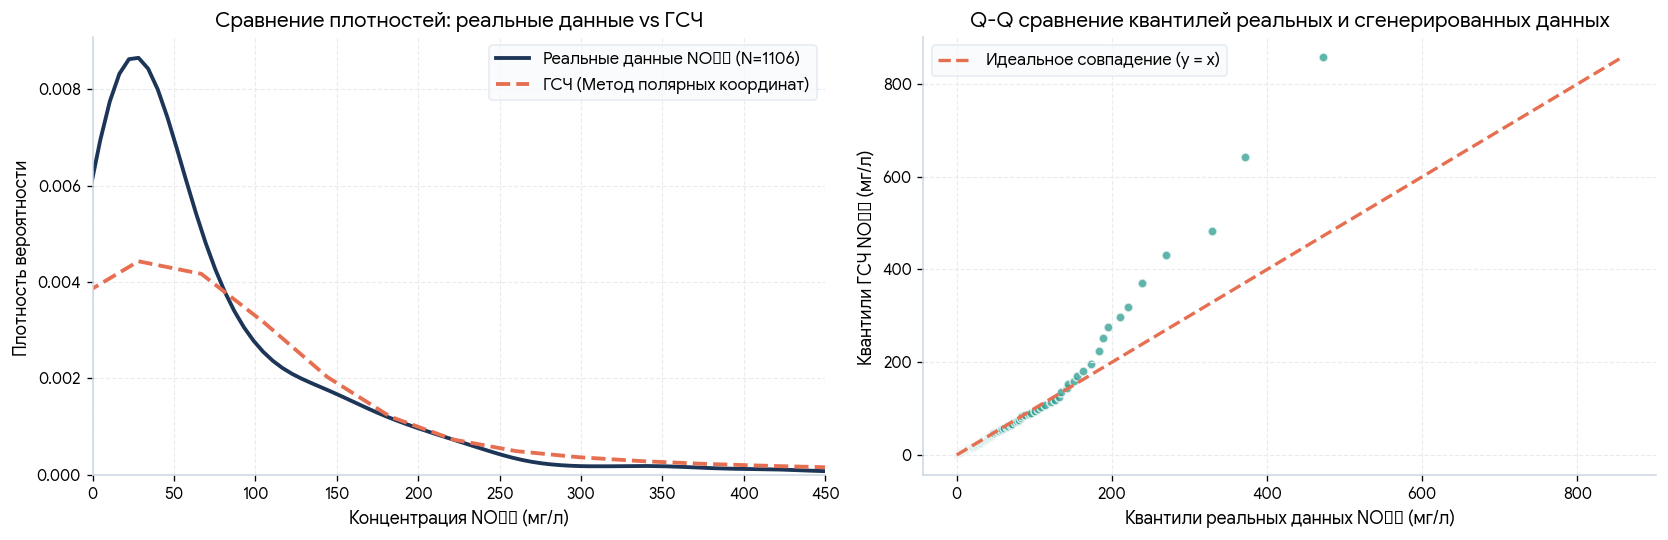

In [5]:
# Верификация генератора случайных чисел по методу полярных координат
display(rng_comp_df)


## <a id="sec6"></a>6. Итоговые выводы и таблица критериев

- Выполнено дополнительное задание **КТвД** на базе объединённого датасета мониторинга подземных вод Теланганы ($N = 1106$): доказана стохастическая природа $\text{pH}$ и $\text{NO}_3^-$, проведён EDA и нормализация ($Z$-преобразование $\ln \text{NO}_3^-$), статистически доказана отрицательная зависимость между $\text{pH}$ и $\text{NO}_3^-$ ($\rho = -0.112$, $p < 0.001$).
- Реализован и верифицирован генератор случайных чисел по методу полярных координат Марсальи (критерий Колмогорова–Смирнова $p > 0.05$ подтверждает согласие распределений), а также интерактивное приложение на базе **Marimo** (`marimo_rng_app.py`).

| Критерий КТвД | Статус | Реализация |
| :--- | :---: | :--- |
| Отдельный датасет и 2 случайные величины (`pH`, `NO3`) | Выполнено | `ktvd_extra_task/telangana_groundwater_2018_2020.csv` |
| Доказательство стохастичности и зависимости величин | Выполнено | Разделы `#sec2` и `#sec4` (тесты Пирсона и Спирмена) |
| EDA, нормализация, единая стилистика графиков и LaTeX | Выполнено | Раздел `#sec3`, единая палитра и оформление осей |
| Интерактивность для генератора случайных чисел + `marimo` | Выполнено | `ktvd_extra_task/marimo_rng_app.py` (запуск: `marimo edit marimo_rng_app.py`) |
